# Removing outliers with pandas



This notebook demonstrates outlier trimming with plain pandas using the California Housing dataset. We compare three ways to calculate limits: the IQR proximity rule, the normal-distribution rule, and quantile limits.



An outlier is not automatically a bad row. First check whether it is a data-entry error, a valid rare observation, or a different population. Trimming is appropriate only when removing the observation is defensible.

## Learning goals



- Understand why extreme values can affect statistics and models.

- Learn how to calculate lower and upper limits from training data.

- Remove observations with pandas Boolean filtering.

- Compare how different rules remove different numbers of rows.

- Avoid leakage by never learning limits from the test set.

In [1]:
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.datasets import fetch_california_housing

from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid',context='notebook')

## 1. Load and split the data



MedInc means median income in a California district. We split first because all outlier limits must be learned from the training data only. The test set represents future, unseen data.

In [2]:
housing=fetch_california_housing(as_frame=True)

X=housing.data.copy()

y=housing.target.copy()

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.30,random_state=0)

print('Full feature shape:',X.shape)

print('Training shape:',X_train.shape)

print('Test shape:',X_test.shape)

display(X_train.head())

display(X_train.describe().T.round(3))

Full feature shape: (20640, 8)
Training shape: (14448, 8)
Test shape: (6192, 8)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
1989,1.9750,52.0,2.800000,0.700000,193.0,4.825000,36.73,-119.79
256,2.2604,43.0,3.671480,1.184116,836.0,3.018051,37.77,-122.21
7887,6.2990,17.0,6.478022,1.087912,1387.0,3.810440,33.87,-118.04
4581,1.7199,17.0,2.518000,1.196000,3051.0,3.051000,34.06,-118.28
1993,2.2206,50.0,4.622754,1.161677,606.0,3.628743,36.73,-119.81


,count,mean,std,min,25%,50%,75%,max
MedInc,14448.0,3.867,1.891,0.500,2.571,3.539,4.736,15.000
HouseAge,14448.0,28.619,12.597,1.000,18.000,29.000,37.000,52.000
AveRooms,14448.0,5.423,2.288,0.846,4.452,5.229,6.048,132.533
AveBedrms,14448.0,1.095,0.453,0.333,1.006,1.049,1.100,34.067
Population,14448.0,1425.157,1149.580,3.000,784.000,1165.000,1724.000,35682.000
AveOccup,14448.0,3.041,6.868,0.750,2.427,2.816,3.280,599.714
Latitude,14448.0,35.630,2.140,32.540,33.930,34.260,37.710,41.950
Longitude,14448.0,-119.567,2.007,-124.350,-121.800,-118.490,-118.000,-114.310


## 2. Visualise a candidate outlier variable



A boxplot highlights extreme values while a histogram shows the overall shape. We use MedInc as the demonstration variable, but the same functions can be reused for any numerical column.

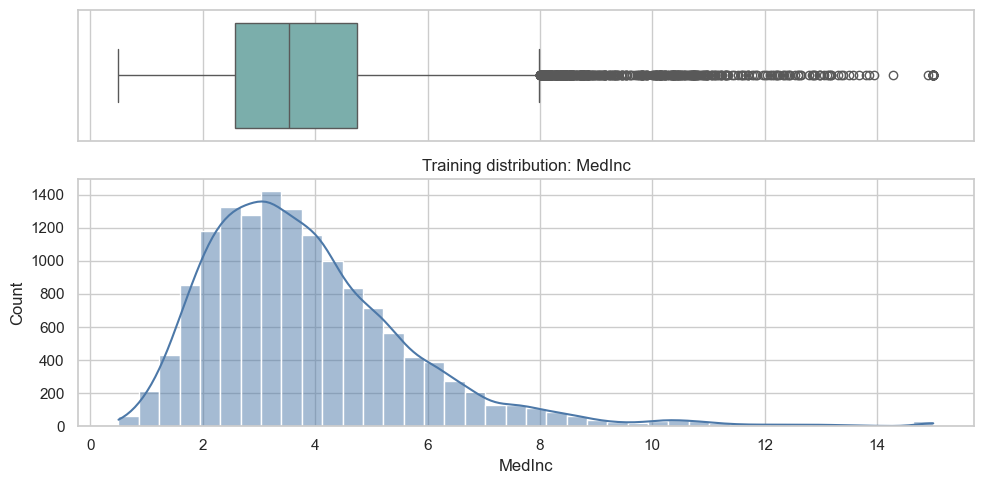

In [3]:
def plot_boxplot_and_hist(frame,variable,title=None):

    fig,(ax_box,ax_hist)=plt.subplots(2,1,sharex=True,figsize=(10,5),gridspec_kw={'height_ratios':(.45,.85)})

    sns.boxplot(x=frame[variable],ax=ax_box,color='#72B7B2')

    sns.histplot(data=frame,x=variable,bins=40,kde=True,ax=ax_hist,color='#4C78A8')

    ax_box.set(xlabel=''); ax_hist.set_title(title or variable)

    plt.tight_layout(); plt.show()

plot_boxplot_and_hist(X_train,'MedInc','Training distribution: MedInc')

## 3. IQR proximity rule



The interquartile range is Q3 minus Q1. With a multiplier of 3, observations below Q1 - 3 x IQR or above Q3 + 3 x IQR are considered extreme. A multiplier of 1.5 is more aggressive; the right choice depends on the domain and the model.

IQR limits: -3.926 to 11.233
Training rows removed: 100
Test rows outside those training limits: 41


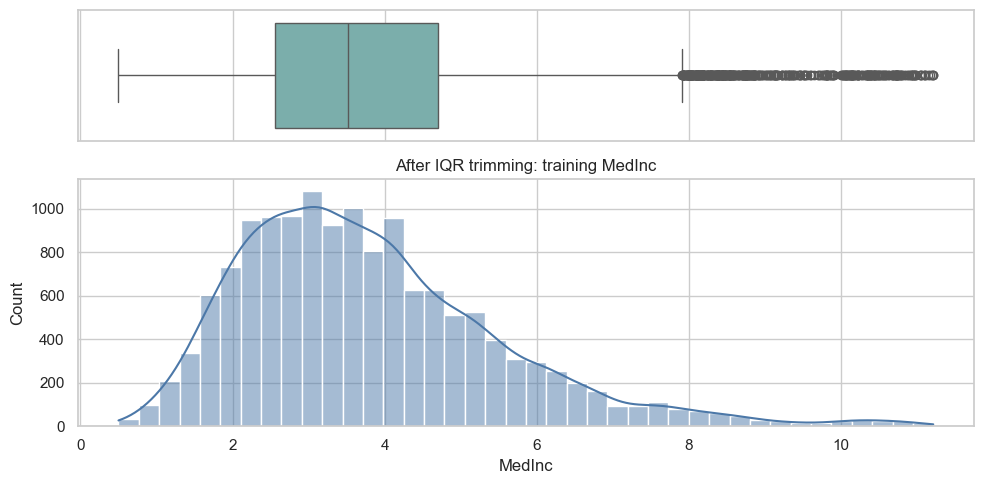

In [4]:
def iqr_limits(frame,variable,fold=3.0):

    q1=frame[variable].quantile(.25)

    q3=frame[variable].quantile(.75)

    iqr=q3-q1

    return q1-fold*iqr,q3+fold*iqr



def trim_between(frame,variable,lower,upper):

    mask=frame[variable].between(lower,upper,inclusive='both')

    return frame.loc[mask].copy(),mask



lower_iqr,upper_iqr=iqr_limits(X_train,'MedInc',fold=3)

X_train_iqr,train_mask_iqr=trim_between(X_train,'MedInc',lower_iqr,upper_iqr)

X_test_iqr,test_mask_iqr=trim_between(X_test,'MedInc',lower_iqr,upper_iqr)

print(f'IQR limits: {lower_iqr:.3f} to {upper_iqr:.3f}')

print('Training rows removed:',(~train_mask_iqr).sum())

print('Test rows outside those training limits:',(~test_mask_iqr).sum())

plot_boxplot_and_hist(X_train_iqr,'MedInc','After IQR trimming: training MedInc')

### Important evaluation note



The limits above were learned only from X_train. Applying those limits to X_test is valid for identifying which future records would be outside the training population. However, do not silently delete test rows just to improve a score: if a model is evaluated on a trimmed population, report that decision and filter the matching target rows as well.

## 4. Normal-distribution rule



If a feature is reasonably bell-shaped, we can use mean +/- a multiple of the standard deviation. A multiplier of 3 is a common starting point. Income is not perfectly normal, so this method is an illustration rather than a guarantee that the assumption is correct.

Normal-rule limits: -1.807 to 9.540
Training rows removed: 237


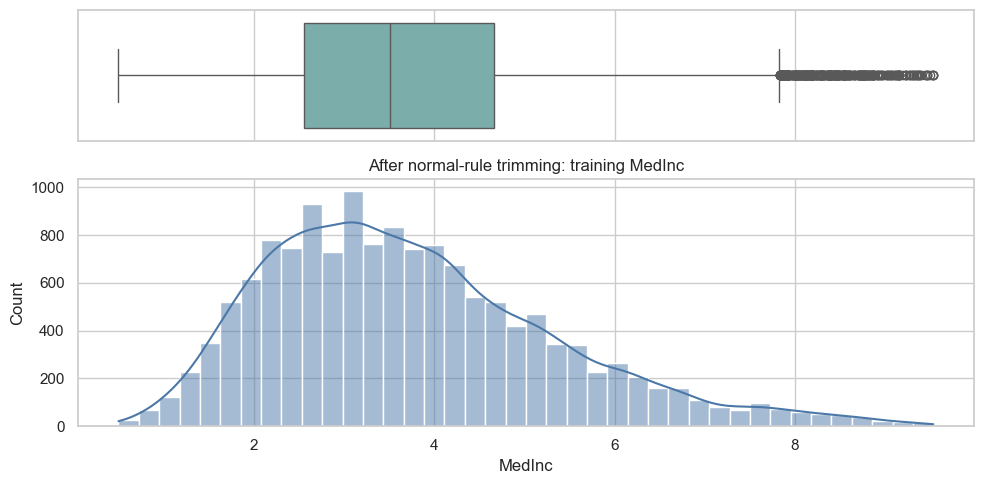

In [5]:
def gaussian_limits(frame,variable,fold=3.0):

    mean=frame[variable].mean()

    std=frame[variable].std()

    return mean-fold*std,mean+fold*std



lower_gaussian,upper_gaussian=gaussian_limits(X_train,'MedInc',fold=3)

X_train_gaussian,mask_gaussian=trim_between(X_train,'MedInc',lower_gaussian,upper_gaussian)

print(f'Normal-rule limits: {lower_gaussian:.3f} to {upper_gaussian:.3f}')

print('Training rows removed:',(~mask_gaussian).sum())

plot_boxplot_and_hist(X_train_gaussian,'MedInc','After normal-rule trimming: training MedInc')

## 5. Quantile rule



Quantile trimming removes a chosen percentage from the tails. Here we keep the middle 90% of training values by using the 5th and 95th percentiles. Quantiles are simple and useful when the business can state an acceptable population percentage.

Quantile limits: 1.602 to 7.285
Training rows removed: 1446


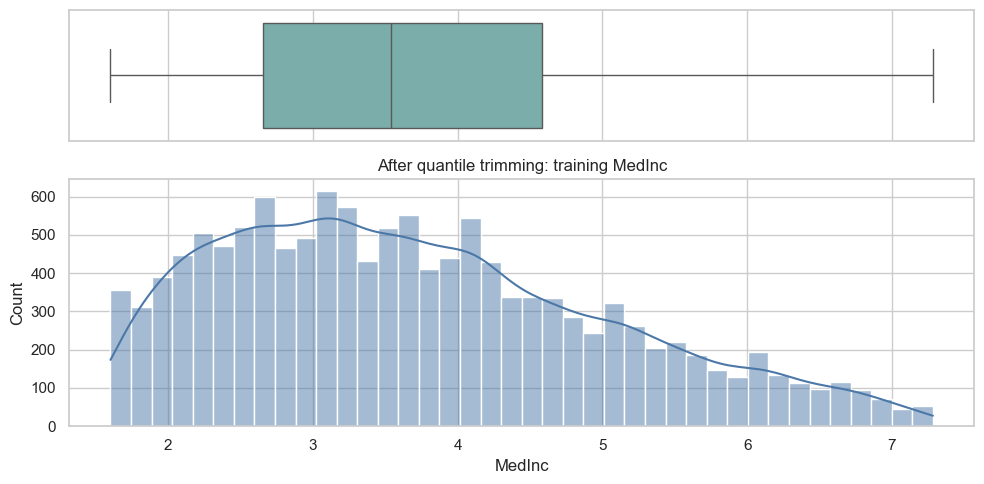

In [6]:
def quantile_limits(frame,variable,lower_quantile=.05,upper_quantile=.95):

    return frame[variable].quantile(lower_quantile),frame[variable].quantile(upper_quantile)



lower_quantile,upper_quantile=quantile_limits(X_train,'MedInc',.05,.95)

X_train_quantile,mask_quantile=trim_between(X_train,'MedInc',lower_quantile,upper_quantile)

print(f'Quantile limits: {lower_quantile:.3f} to {upper_quantile:.3f}')

print('Training rows removed:',(~mask_quantile).sum())

plot_boxplot_and_hist(X_train_quantile,'MedInc','After quantile trimming: training MedInc')

## 6. Compare the rules



Different rules answer different questions. IQR asks whether a value is far from the middle 50%; the normal rule asks whether it is far from the mean in standard-deviation units; quantiles deliberately remove a chosen tail percentage. There is no universal best rule.

,method,lower_limit,upper_limit,training_rows_removed,percentage_removed
0,IQR (fold=3),-3.926,11.233,100,0.692
1,Normal (fold=3),-1.807,9.540,237,1.640
2,Quantiles (5%-95%),1.602,7.285,1446,10.008


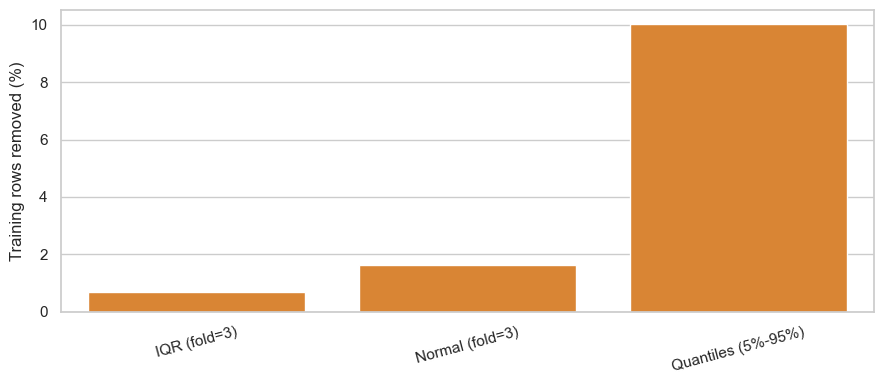

In [7]:
comparison=pd.DataFrame({

    'method':['IQR (fold=3)','Normal (fold=3)','Quantiles (5%-95%)'],

    'lower_limit':[lower_iqr,lower_gaussian,lower_quantile],

    'upper_limit':[upper_iqr,upper_gaussian,upper_quantile],

    'training_rows_removed':[(~train_mask_iqr).sum(),(~mask_gaussian).sum(),(~mask_quantile).sum()],

})

comparison['percentage_removed']=100*comparison['training_rows_removed']/len(X_train)

display(comparison.round(3))



fig,ax=plt.subplots(figsize=(9,4))

sns.barplot(data=comparison,x='method',y='percentage_removed',color='#F58518',ax=ax)

ax.set_ylabel('Training rows removed (%)'); ax.set_xlabel(''); ax.tick_params(axis='x',rotation=15)

plt.tight_layout(); plt.show()

## 7. Reusable pandas pattern



The core pandas operation is a Boolean mask. Values between the limits are kept; values outside are removed. Always use a copy after filtering so later edits do not produce confusing chained-assignment warnings.

In [8]:
lower,upper=iqr_limits(X_train,'MedInc',fold=3)

inliers=X_train['MedInc'].between(lower,upper,inclusive='both')

X_train_clean=X_train.loc[inliers].copy()

y_train_clean=y_train.loc[inliers].copy()

print('X rows before/after:',len(X_train),len(X_train_clean))

print('y rows before/after:',len(y_train),len(y_train_clean))

assert len(X_train_clean)==len(y_train_clean)

display(X_train_clean['MedInc'].describe().to_frame('MedInc'))

X rows before/after: 14448 14348
y rows before/after: 14448 14348


,MedInc
count,14348.000000
mean,3.800948
std,1.721683
min,0.499900
25%,2.565075
50%,3.525000
75%,4.705075
max,11.218500


## 8. Practical decision guide



- Keep an extreme value when it is valid and part of the population you want to predict.

- Correct or remove it when it is impossible or clearly a data-entry error.

- Trim only when the analysis is explicitly about the inlier population and the loss of rows is acceptable.

- Prefer capping, transformations, or robust models when valid extremes must remain.

- Fit all statistical limits on training data only, and document the number of affected records.



Outlier trimming is a modelling decision, not just a cleaning command. Compare the resulting distributions and validation metrics with a baseline that keeps the original rows.

## Summary



This notebook used pandas to calculate IQR, normal-distribution, and quantile limits, filtered rows with Boolean masks, and visualised the effect of each rule. The most important habits are to investigate the meaning of an extreme value, fit limits on training data only, keep X and y aligned, and report how many records were removed.